# 01 — Análise exploratória e divisão por paciente

NIH ChestX-ray14 (amostra do Kaggle). Gera `data/splits/{train,validation,test}.csv`.

In [1]:
import os, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("triagem-raio-x").exists():
        os.system("git clone https://github.com/LuizCenci/triagem-raio-x")
    os.chdir("triagem-raio-x")
    os.system("pip install -q kagglehub seaborn scikit-learn pandas")
else:
    os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())

In [2]:
import matplotlib
matplotlib.use("Agg") if "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.config import RESULTS_DIR, SPLITS_DIR, CLASSES, AGE_LABELS
from src.download import download_dataset, find_metadata_csv
from src.metadata import load_metadata, attach_paths
from src.split import patient_split, save_splits, SPLIT_NAMES

FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
root = download_dataset()
csv = find_metadata_csv(root)
print(root, csv, sep=" | ")

C:\Users\luiza\OneDrive\Documentos\UTFPR\triagem-raio-x\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\luiza\.cache\kagglehub\datasets\nih-chest-xrays\sample\versions\4 | C:\Users\luiza\.cache\kagglehub\datasets\nih-chest-xrays\sample\versions\4\sample_labels.csv


In [3]:
df = load_metadata(csv)
df_img = attach_paths(df, root)
print(f"linhas no CSV: {len(df)} | com imagem em disco: {len(df_img)} | ausentes: {len(df) - len(df_img)}")
print(f"pacientes: {df_img.patient_id.nunique()} | idades nulas: {df_img.age.isna().sum()}")

linhas no CSV: 5606 | com imagem em disco: 5606 | ausentes: 0
pacientes: 4230 | idades nulas: 1


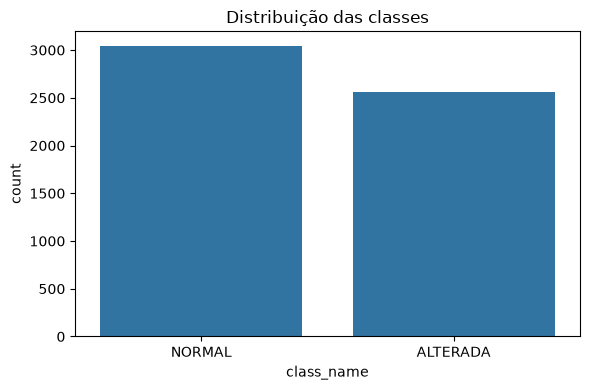

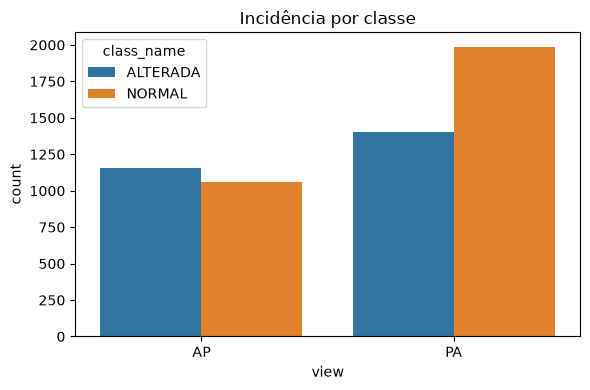

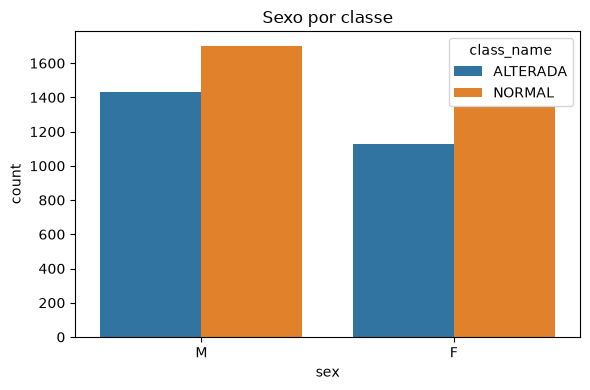

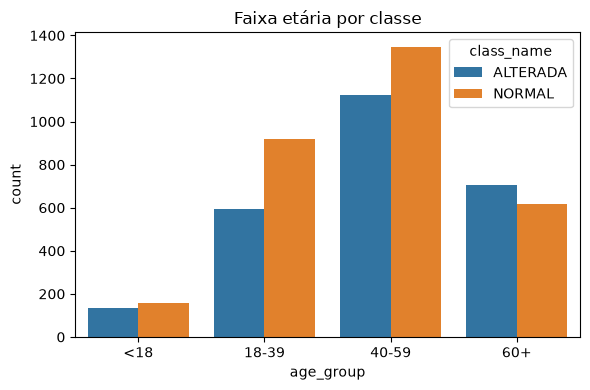

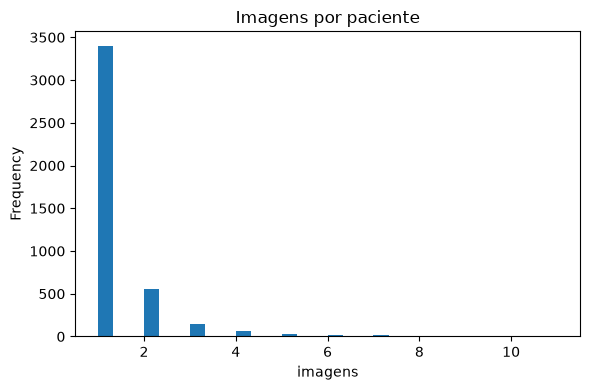

class_name
NORMAL      0.543
ALTERADA    0.457
Name: proportion, dtype: float64


In [4]:
def barplot(data, x, hue, title, fname, order=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.countplot(data=data, x=x, hue=hue, order=order, ax=ax)
    ax.set_title(title); fig.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

d = df_img
barplot(d, "class_name", None, "Distribuição das classes", "eda_classes.png", order=list(CLASSES))
barplot(d, "view", "class_name", "Incidência por classe", "eda_view.png")
barplot(d, "sex", "class_name", "Sexo por classe", "eda_sex.png")
barplot(d, "age_group", "class_name", "Faixa etária por classe", "eda_age.png", order=list(AGE_LABELS))
fig, ax = plt.subplots(figsize=(6, 4))
d.groupby("patient_id").size().plot.hist(bins=30, ax=ax)
ax.set_title("Imagens por paciente"); ax.set_xlabel("imagens"); fig.tight_layout()
fig.savefig(FIG / "eda_images_per_patient.png", dpi=150); plt.show()
print(d.class_name.value_counts(normalize=True).round(3))

In [5]:
splits = patient_split(df_img.drop(columns="path"))
rows = []
for name in SPLIT_NAMES:
    s = splits[name]
    rows.append({"split": name, "imagens": len(s), "pacientes": s.patient_id.nunique(),
                 "NORMAL": (s.label == 0).sum(), "ALTERADA": (s.label == 1).sum(),
                 "% ALTERADA": round(100 * s.label.mean(), 1)})
pd.DataFrame(rows)

,split,imagens,pacientes,NORMAL,ALTERADA,% ALTERADA
0,train,3931,2961,2126,1805,45.9
1,validation,531,423,304,227,42.7
2,test,1144,846,614,530,46.3


In [6]:
save_splits(splits, SPLITS_DIR)
print([str(p) for p in sorted(SPLITS_DIR.glob("*.csv"))])

['C:\\Users\\luiza\\OneDrive\\Documentos\\UTFPR\\triagem-raio-x\\data\\splits\\test.csv', 'C:\\Users\\luiza\\OneDrive\\Documentos\\UTFPR\\triagem-raio-x\\data\\splits\\train.csv', 'C:\\Users\\luiza\\OneDrive\\Documentos\\UTFPR\\triagem-raio-x\\data\\splits\\validation.csv']


## Conclusões

- **Classes:** ver proporção acima; se a classe minoritária ficar abaixo de 40%, a Etapa 2 usa `class_weight="balanced"` calculado no treino.
- **Divisão:** por paciente (`GroupShuffleSplit`, semente 42), sem interseção de pacientes entre os splits (verificado por `assert_no_patient_overlap`).
- **Limitações:** rótulos extraídos automaticamente de laudos (ruído de anotação), possíveis atalhos visuais e amostra de uma única origem.